# Tianhao Wu / Fairy-6b：真实模型与外部特征实验

**EXPLORATORY — NOT APPROVED AS FINAL RESULTS**

本Notebook是本地最终实验的轻量GitHub审阅版。复用PR #5已有模型/外部模块，新增真实长期数据实验及外部特征整合。所有图表来自同一历史运行 `run-20261030T141916Z-36b86a` 的真实预测/指标，默认离线读取并重算，不会训练、联网或改写实验产物。

标签是**预测后30分钟内持续恢复的确认**，与proposal“恢复开始”存在差异；正式口径仍待团队确认。本次只包含30分钟、逻辑回归和决策树，不重复实现队友的RF/HGB。

阅读顺序：产物核验 → 数据划分 → 特征与来源 → 模型对比 → 验证集选择 → 解释和错误 → 复现及限制。

In [1]:
from pathlib import Path
import sys, json, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').is_file() and (p/'experiments/tianhao/results').is_dir())
BASE=ROOT/'experiments/tianhao'; R=BASE/'results'
spec=importlib.util.spec_from_file_location('verify_review',BASE/'verify_review.py')
verification=importlib.util.module_from_spec(spec);spec.loader.exec_module(verification)
display(verification.verify())
pred=pd.read_parquet(R/'predictions.parquet')
metrics=pd.read_csv(R/'metrics_summary.csv')
plan=json.loads((R/'predeclared_plan.json').read_text(encoding='utf-8'))
provenance=json.loads((R/'provenance.json').read_text(encoding='utf-8'))
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
print('Original engine:',provenance['original_engine_commit'])
print('Prediction rows:',len(pred),'| Source run:',provenance['original_run_id'])

{'status': 'passed',
 'checks': 568,
 'prediction_rows': 95186,
 'arms': 14,
 'note': 'Offline output checks only; source-time checks remain in the historical real-run verification. No scientific approval.'}

Original engine: 4fd706e7ea5b0df970da9b922704c9068677555d
Prediction rows: 95186 | Source run: run-20261030T141916Z-36b86a


## 1. 数据划分与未知标签

7597事件来自24个车道单位，并不代表全香港。2023年1月用于拟合参考速度；训练从2023年2月起至2024年底，验证2025年，测试2026年1–9月。30分钟已知标签6799，未知标签798，未知不当负例。每个split的14个实验臂使用相同事件、标签及预测时点。

共享队列保留最大60分钟结果窗口及10分钟可用性延迟的边界约束；本次不修改队友标签。不同车道或事件可能相关，不能把每行当独立统计样本。

,events,known,positive,negative,unknown
split,,,,,
train,3833,3428,1449,1979,405
validation,2235,2008,890,1118,227
test,1529,1363,629,734,166


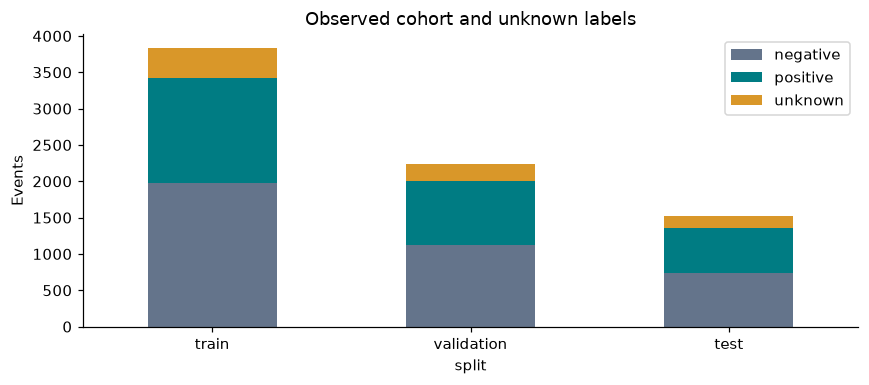

In [2]:
cohort=pd.read_csv(R/'cohort_summary.csv').set_index('split').reindex(['train','validation','test'])
display(cohort)
ax=cohort[['negative','positive','unknown']].plot.bar(stacked=True,color=['#64748B','#007C83','#D99729'],figsize=(8,3.6),rot=0)
ax.set_ylabel('Events');ax.set_title('Observed cohort and unknown labels');plt.tight_layout();plt.show()

## 2. 特征、时间边界与外部来源

local：速度、速度比例、参考速度、有效槽数、确认时长。history：截止拥堵确认分箱的过去15分钟速度变化、均值、斜率与有效分箱数。flow：截止确认分箱前5分钟的同车道观测流量/占有率中位数与槽数，**跨午夜读取前一天**。

每条观测必须在预测时点已可获取；通常 `prediction_time` 比 `onset_confirmed_at` 晚10分钟。流量是观测到的30秒区间计数，不是每小时流量；缺失测量不补0。

calendar：小时、星期、周末、官方假期及前后一天，公告必须在预测前发布。weather：京士柏温度/风速，按档案捕获时间回放，观测年龄不超过60分钟；这是区域代理，不是每条道路的最近站。

来源：[长期交通数据Release](https://github.com/CityuHK-wyj/hk-traffic-recovery-prediction/releases/tag/data-long-window-2023-2026-v1)、[历史档案API](https://data.gov.hk/en/help/api-spec)、[2023假期](https://www.info.gov.hk/gia/general/202205/13/P2022051000340.htm)、[2024假期](https://www.info.gov.hk/gia/general/202305/25/P2023052500208p.htm)、[2025假期](https://www.info.gov.hk/gia/general/202405/03/P2024043000417.htm)、[2026假期](https://www.info.gov.hk/gia/general/202505/16/P2025051300353.htm)。详细URL、档案时间、来源哈希见结果目录清单。

日历组含多个因素，不能把整组效果归因于假期。天气整合在7597事件中温度缺5、风速缺22；模型使用训练集拟合的中位数填补及缺失标记。

In [3]:
display(pd.DataFrame([{'group':g,'features':', '.join(v)} for g,v in plan['feature_groups'].items()]))
display(pd.read_csv(R/'feature_missingness.csv').query('missing > 0'))

,group,features
0,local,"speed_kmh, speed_ratio, baseline_kmh, valid_sl..."
1,history,"speed_change_15m_ratio, speed_mean_15m_ratio, ..."
2,flow,"volume_median_per_observed_30s, occupancy_medi..."
3,calendar,"hour_sin, hour_cos, dow_sin, dow_cos, is_weeke..."
4,weather,"temperature_c, wind_speed_kmh, temperature_age..."


,split,group,feature,n,missing
21,test,weather,temperature_c,1529,2
22,test,weather,wind_speed_kmh,1529,14
48,train,weather,temperature_c,3833,3
49,train,weather,wind_speed_kmh,3833,2
76,validation,weather,wind_speed_kmh,2235,6


## 3. 冻结实验及完整测试对比

4个基准：多数类、训练正例比例、速度比例规则、速度趋势规则。两个学习模型各5组累加特征，共14实验臂。原有引擎使用训练集拟合预处理、验证集log loss选参数；阈值0.5，不用训练＋验证重新拟合。趋势规则只用验证集Macro-F1选阈值。规则分数不是概率，故其log loss/Brier为空。

下图是描述性比较；未计算显著性或因果效果。测试结果全部列出，但不按测试最高分选择展示模型。

,model,feature_set,macro_f1,balanced_accuracy,roc_auc,log_loss
0,decision_tree,local,0.5823,0.5826,0.6277,0.6719
3,decision_tree,local+history,0.5966,0.5997,0.6276,0.6542
6,decision_tree,local+history+flow,0.6170,0.6200,0.6637,0.6549
9,decision_tree,local+history+flow+calendar,0.6290,0.6384,0.7007,0.6264
12,decision_tree,local+history+flow+calendar+weather,0.6290,0.6384,0.7007,0.6264
15,logistic_regression,local,0.4097,0.5005,0.5196,0.6903
18,logistic_regression,local+history,0.6202,0.6208,0.6672,0.6515
21,logistic_regression,local+history+flow,0.6241,0.6261,0.6686,0.6518
24,logistic_regression,local+history+flow+calendar,0.6395,0.6415,0.6896,0.6450
27,logistic_regression,local+history+flow+calendar+weather,0.6414,0.6428,0.6884,0.6457


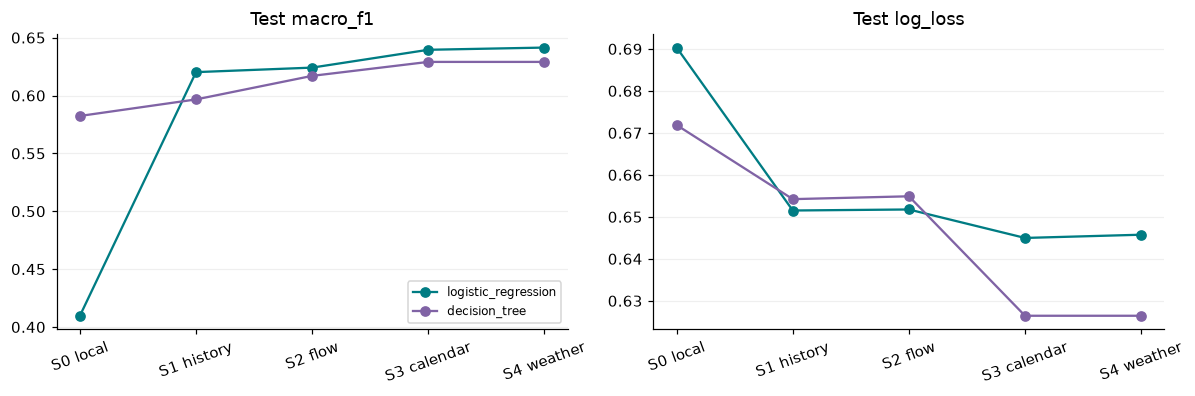

In [4]:
order=['+'.join(g) for g in plan['feature_sets']]
test=metrics.loc[metrics.split.eq('test')].copy()
display(test[['model','feature_set','macro_f1','balanced_accuracy','roc_auc','log_loss']].round(4))
fig,axes=plt.subplots(1,2,figsize=(11,3.7))
for model,color in [('logistic_regression','#007C83'),('decision_tree','#8063A5')]:
    t=test.loc[test.model.eq(model)].set_index('feature_set').reindex(order)
    for ax,metric in zip(axes,['macro_f1','log_loss']):
        ax.plot(range(5),t[metric],marker='o',color=color,label=model)
        ax.set_xticks(range(5),['S0 local','S1 history','S2 flow','S3 calendar','S4 weather'],rotation=20)
        ax.set_title('Test '+metric);ax.grid(axis='y',alpha=.2)
axes[0].legend(fontsize=8);fig.tight_layout();plt.show()

## 4. 用验证集选择展示模型

候选先按验证集log loss升序，再在相同分数时选择更少特征。验证集选择：决策树＋local/history/flow/calendar。天气树没有形成新的测试预测。

这个模型测试Macro-F1约0.6290、balanced accuracy约0.6384、ROC-AUC约0.7007。逻辑回归加入天气后Macro-F1略升，但log loss与ROC-AUC未同步改善，不能声称天气有稳定收益。

,model,feature_set,log_loss,macro_f1
11,decision_tree,local+history+flow+calendar,0.651014,0.608685
14,decision_tree,local+history+flow+calendar+weather,0.651014,0.608685
5,decision_tree,local+history,0.663828,0.577120
26,logistic_regression,local+history+flow+calendar,0.665268,0.597043
29,logistic_regression,local+history+flow+calendar+weather,0.665354,0.602329
2,decision_tree,local,0.667143,0.586455
23,logistic_regression,local+history+flow,0.668882,0.580402
20,logistic_regression,local+history,0.670051,0.574651
8,decision_tree,local+history+flow,0.670190,0.595023
17,logistic_regression,local,0.685967,0.381680


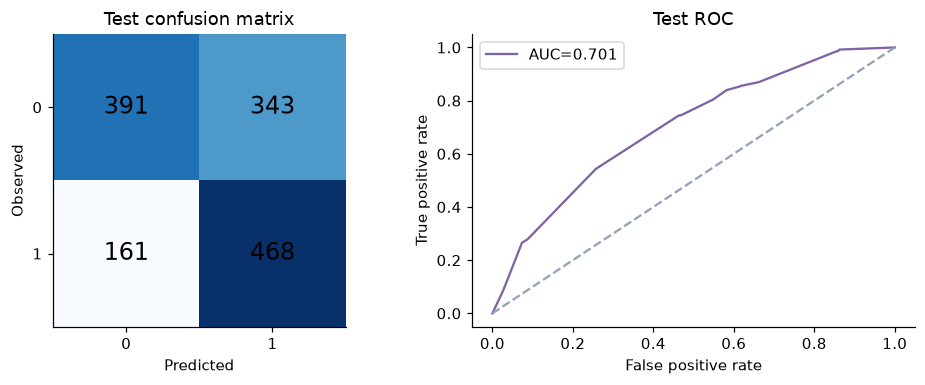

In [5]:
candidate=metrics.loc[metrics.split.eq('validation') & metrics.model.isin(['logistic_regression','decision_tree'])].copy()
candidate['n_groups']=candidate.feature_set.str.count(r'\+')+1
candidate=candidate.sort_values(['log_loss','n_groups','model'],kind='stable')
display(candidate[['model','feature_set','log_loss','macro_f1']].round(6))
selected=candidate.iloc[0];model,features=selected.model,selected.feature_set
assert model=='decision_tree' and features=='local+history+flow+calendar'
p=pred.loc[pred.model.eq(model)&pred.feature_set.eq(features)&pred.split.eq('test')].copy()
from sklearn.metrics import confusion_matrix,roc_curve,roc_auc_score
cm=confusion_matrix(p.y_true,p.y_pred,labels=[0,1]);fpr,tpr,_=roc_curve(p.y_true,p.y_score)
fig,axes=plt.subplots(1,2,figsize=(9,3.6))
axes[0].imshow(cm,cmap='Blues')
for i in range(2):
    for j in range(2):axes[0].text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=16)
axes[0].set_xticks([0,1],['0','1']);axes[0].set_yticks([0,1],['0','1']);axes[0].set_xlabel('Predicted');axes[0].set_ylabel('Observed');axes[0].set_title('Test confusion matrix')
axes[1].plot(fpr,tpr,color='#8063A5',label=f'AUC={roc_auc_score(p.y_true,p.y_score):.3f}');axes[1].plot([0,1],[0,1],'--',color='#94A3B8');axes[1].set_xlabel('False positive rate');axes[1].set_ylabel('True positive rate');axes[1].set_title('Test ROC');axes[1].legend();fig.tight_layout();plt.show()

## 5. 结果解释与错误分布

树的重要性表示这棵树中用于分裂的贡献，不表示因果效应或特征的普遍价值。先查看验证集选中的同一模型，再核对错误数量；小组样本量很小时不按误差率排名推断道路难度。

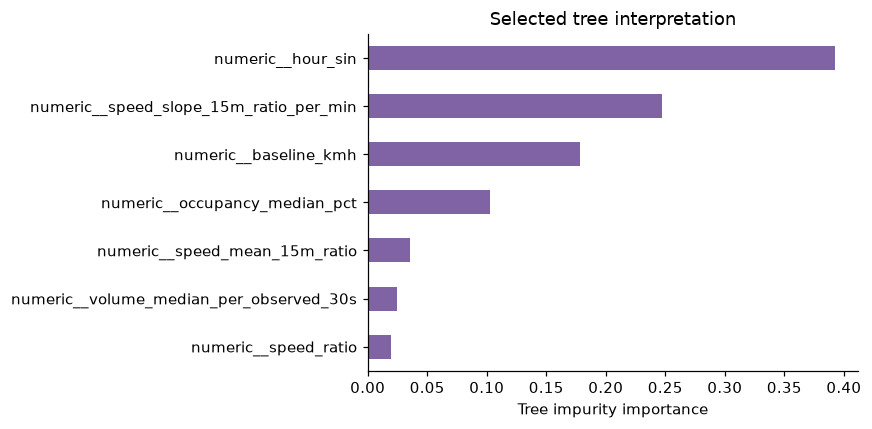

{'model': 'tree',
 'feature_set': 'local+history+flow+calendar',
 'horizon_min': 30,
 'parameters': {'max_depth': 4, 'min_samples_leaf': 10, 'class_weight': None},
 'validation_log_loss': 0.6510141818634149,
 'train_rows': 3428,
 'validation_rows': 2008,
 'test_rows': 1363,
 'refit_after_selection': False,
 'tree_depth': 4,
 'tree_leaves': 15}

|--- numeric__speed_slope_15m_ratio_per_min <= -0.04
|   |--- numeric__hour_sin <= 0.39
|   |   |--- numeric__baseline_kmh <= 73.50
|   |   |   |--- numeric__speed_mean_15m_ratio <= 0.46
|   |   |   |   |--- class: 0
|   |   |   |--- numeric__speed_mean_15m_ratio >  0.46
|   |   |   |   |--- class: 1
|   |   |--- numeric__baseline_kmh >  73.50
|   |   |   |--- numeric__baseline_kmh <= 76.00
|   |   |   |   |--- class: 0
|   |   |   |--- numeric__baseline_kmh >  76.00
|   |   |   |   |--- class: 0
|   |--- numeric__hour_sin >  0.39
|   |   |--- numeric__speed_slope_15m_ratio_per_min <= -0.04
|   |   |   |--- numeric__speed_ratio <= 0.22
|   |   |   |   |--- class: 1
|   |   |   |--- numeric__speed_ratio >  0.22
|   |   |   |   |--- class: 1
|   |   |--- numeric__speed_slope_15m_ratio_per_min >  -0.04
|   |   |   |--- numeric__occupancy_median_pct <= 45.00
|   |   |   |   |--- class: 1
|   |   |   |--- numeric__occupancy_median_pct >  45.00
|   |   |   |   |--- class: 0
|--- numeric__spe

In [6]:
importance=pd.read_csv(R/'interpretation.csv')
v=importance.loc[importance.model.eq(model)&importance.feature_set.eq(features)&importance.value.gt(0)].sort_values('value').tail(12)
ax=v.plot.barh(x='feature',y='value',legend=False,figsize=(8,4),color='#8063A5');ax.set_xlabel('Tree impurity importance');ax.set_ylabel('');ax.set_title('Selected tree interpretation');plt.tight_layout();plt.show()
summaries=json.loads((R/'model_summaries.json').read_text(encoding='utf-8'))
summary=next(s for s in summaries if s['model']=='tree' and s['feature_set']==features)
display({k:v for k,v in summary.items() if k!='tree_text'})
print(summary['tree_text'])

In [7]:
errors=pd.read_csv(R/'error_groups.csv')
selected_errors=errors.loc[errors.model.eq(model)&errors.feature_set.eq(features)]
display(selected_errors.loc[selected_errors.dimension.eq('peak')])
display(selected_errors.loc[selected_errors.dimension.eq('detector_id')].sort_values('n',ascending=False).head(12))
display(p[['event_id','prediction_time','y_true','y_pred','y_score','model','feature_set']].head(10))

,model,feature_set,dimension,group,n,errors,error_rate,macro_f1
342,decision_tree,local+history+flow+calendar,peak,off_peak,587,265,0.451448,0.547665
343,decision_tree,local+history+flow+calendar,peak,peak,776,239,0.307990,0.690674


,model,feature_set,dimension,group,n,errors,error_rate,macro_f1
78,decision_tree,local+history+flow+calendar,detector_id,AID01108,345,104,0.301449,0.683598
83,decision_tree,local+history+flow+calendar,detector_id,AID01117,304,124,0.407895,0.478270
77,decision_tree,local+history+flow+calendar,detector_id,AID01107,223,93,0.417040,0.554890
76,decision_tree,local+history+flow+calendar,detector_id,AID01106,154,37,0.240260,0.654478
86,decision_tree,local+history+flow+calendar,detector_id,AID01126,73,37,0.506849,0.489703
87,decision_tree,local+history+flow+calendar,detector_id,AID01127,63,27,0.428571,0.549165
93,decision_tree,local+history+flow+calendar,detector_id,AID01136,36,15,0.416667,0.575138
95,decision_tree,local+history+flow+calendar,detector_id,AID01202,21,7,0.333333,0.400000
85,decision_tree,local+history+flow+calendar,detector_id,AID01124,20,5,0.250000,0.641577
79,decision_tree,local+history+flow+calendar,detector_id,AID01111,19,9,0.473684,0.424242


,event_id,prediction_time,y_true,y_pred,y_score,model,feature_set
80225,da25cad6d67e889a4d80,2026-01-01 17:50:00+08:00,1,1,0.564644,decision_tree,local+history+flow+calendar
80226,e422fbbb1c133d41a692,2026-01-02 18:50:00+08:00,1,1,0.502600,decision_tree,local+history+flow+calendar
80227,4c897543402ae0c0bf09,2026-01-02 18:50:00+08:00,1,0,0.229947,decision_tree,local+history+flow+calendar
80228,3f2a070c5615d21fffe1,2026-01-05 08:10:00+08:00,0,0,0.043307,decision_tree,local+history+flow+calendar
80229,dca98a4f5359bfedc929,2026-01-05 08:30:00+08:00,1,1,0.685393,decision_tree,local+history+flow+calendar
80230,a48e456de7555a519704,2026-01-05 08:50:00+08:00,1,1,0.685393,decision_tree,local+history+flow+calendar
80231,d455da3f61bf7ce8aa03,2026-01-05 17:15:00+08:00,0,1,0.564644,decision_tree,local+history+flow+calendar
80232,28f4e657107727c0252f,2026-01-05 17:35:00+08:00,0,0,0.229947,decision_tree,local+history+flow+calendar
80233,09d0298c9023c9eeaafd,2026-01-05 18:50:00+08:00,0,1,0.502600,decision_tree,local+history+flow+calendar
80234,648ce796c5c0f383ac6a,2026-01-06 08:05:00+08:00,0,0,0.043307,decision_tree,local+history+flow+calendar


## 6. 复现、核验与仍需队友确认的部分

仓库版保留原始真实预测字节，`verify_review.py` 会核对历史输出SHA256、配对队列、时间划分及全部指标/混淆矩阵。历史完整核验237项包含原始天气成员、流量跨午夜、时间水位及训练集预处理，记录为 `results/verification.json`；它需要未上传的大型来源与拟合文件，轻量核验不能代替原始源核验。

[复现说明](../experiments/tianhao/README.md)提供从官方来源下载、核验、准备和重新训练的命令。每次新建运行目录；脚本路径已移植到仓库目录，原始科学引擎版本、脚本哈希和软件版本见 `results/provenance.json`。上传整理没有重新训练；主分支新版本与历史结果之间的差异要显式记录。

**未完成/依赖：** 雨量未建立安全历史重放；事故缺全时段回放与位置消歧；大型活动源存在事后描述且无可验证的预测时点历史版本；邻路特征仍缺人工确认。没有把这些缺失写成0。15/60分钟、RF/HGB对比未包含在本次运行。

**研究限制：** 24车道选择偏差、跨年设备/方向身份、2023固定正常参考漂移、稀疏分箱、未知标签排除、共同拥堵相关性及恢复确认与proposal恢复开始之间的差异仍然存在。需与数据/空间/模型队友确认后才能形成正式结论。